# 00 — Modelo e linha de base da variante exploratória

> **Artefato deste projeto.** O Booster em `models/` foi retreinado com `scale_pos_weight=13.882494684620836`; o corte descritivo é 0,50. Por padrão, este notebook carrega e verifica esse modelo congelado. Um novo retreino é opcional e exige o comando `python scripts/executar_notebooks.py 00 00 --retrain-model`, que substitui o Booster e o manifesto. Os testes percorrem toda a grade sem critério arbitrário de parada ou aprovação. O *early stopping* pertence ao ajuste do modelo, não à varredura de estresse.

Métricas supervisionadas centrais: **Brier**, **AUC ROC**, **área trapezoidal sob a curva precisão–recall (PR-AUC)** e **KS do modelo**. `AP` é mantida separada, pois não é igual à área trapezoidal. Recall e precisão no corte 0,50 são descritores de decisão, não critérios de falha. `cs-test.csv` não tem rótulos e só recebe diagnósticos não supervisionados.


In [1]:
from pathlib import Path
import os

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )

# A execução padrão usa o Booster congelado; o executor só retreina com --retrain-model.
RETRAIN_MODEL = os.environ.get("CREDIT_STRESS_RETRAIN_MODEL") == "1"


In [2]:
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve, auc)
from sklearn.calibration import calibration_curve
from IPython.display import display

SEED = 33
THRESHOLD = 0.50
P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / "cs-training.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.")
OUT_DIR = TABLES_DIR
OUT_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / 'model_class_retreinado.json'
MANIFEST_PATH = MODEL_DIR / 'manifesto_modelo.json'
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]
TARGET = 'SeriousDlqin2yrs'
sns.set_theme(style="whitegrid", context="notebook")
print("Python", platform.python_version(), "| XGBoost", xgb.__version__)
print("Saída:", OUT_DIR)

Python 3.12.10 | XGBoost 3.0.0
Saída: .\results\tables


## 1. Validar os arquivos e a população

O identificador `Unnamed: 0` é excluído. Faltantes são preservados, como no notebook original; o XGBoost os trata nativamente.

In [3]:
train_path = DATA_DIR / "cs-training.csv"
test_path = DATA_DIR / "cs-test.csv"
assert train_path.exists() and test_path.exists(), "Ajuste DATA_DIR para a pasta dos CSVs."
df = pd.read_csv(train_path).drop(columns=['Unnamed: 0'])
df_unlabeled = pd.read_csv(test_path).drop(columns=['Unnamed: 0'])
assert list(df[FEATURES].columns) == FEATURES
assert set(df[TARGET].dropna().unique()) == {0, 1}
assert df[TARGET].notna().all()
assert df_unlabeled[TARGET].isna().all()
assert len(df) == 150000 and len(df_unlabeled) == 101503
resumo = pd.DataFrame({
    'treino_completo_missing_%': 100*df[FEATURES].isna().mean(),
    'cs_test_missing_%': 100*df_unlabeled[FEATURES].isna().mean(),
    'mediana_training': df[FEATURES].median(),
    'mediana_cs_test': df_unlabeled[FEATURES].median(),
})
display(resumo.round(3))
print(f"Training: {len(df):,} linhas, prevalência {df[TARGET].mean():.3%}")
print(f"cs-test: {len(df_unlabeled):,} linhas, rótulos observados {df_unlabeled[TARGET].notna().sum()}")

,treino_completo_missing_%,cs_test_missing_%,mediana_training,mediana_cs_test
RevolvingUtilizationOfUnsecuredLines,0.000,0.000,0.154,0.153
age,0.000,0.000,52.000,52.000
NumberOfTime30-59DaysPastDueNotWorse,0.000,0.000,0.000,0.000
DebtRatio,0.000,0.000,0.367,0.364
MonthlyIncome,19.821,19.805,5400.000,5400.000
NumberOfOpenCreditLinesAndLoans,0.000,0.000,8.000,8.000
NumberOfTimes90DaysLate,0.000,0.000,0.000,0.000
NumberRealEstateLoansOrLines,0.000,0.000,1.000,1.000
NumberOfTime60-89DaysPastDueNotWorse,0.000,0.000,0.000,0.000
NumberOfDependents,2.616,2.587,0.000,0.000


Training: 150,000 linhas, prevalência 6.684%
cs-test: 101,503 linhas, rótulos observados 0


## 2. Reproduzir o split

O holdout `X_test` permanece intocado até a avaliação. As classes não foram reamostradas no caminho efetivo do notebook original.

In [4]:
X = df[FEATURES]
y = df[TARGET].astype(int)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=SEED)
for nome, yy in [('treino', y_train), ('validação', y_val), ('holdout', y_test)]:
    print(f"{nome:10s}: n={len(yy):6,d}, positivos={yy.sum():5,d}, prevalência={yy.mean():.3%}")
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=FEATURES, enable_categorical=True)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=FEATURES, enable_categorical=True)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=FEATURES, enable_categorical=True)

treino    : n=104,996, positivos=7,055, prevalência=6.719%
validação : n=22,504, positivos=1,471, prevalência=6.537%
holdout   : n=22,500, positivos=1,500, prevalência=6.667%


## 3. Treinar `model_class`

Os parâmetros abaixo são os fornecidos no pedido. `n_estimators=800` vira `num_boost_round=800`, como em `model_final.ipynb`; `enable_categorical=True` pertence a `DMatrix`, não ao dicionário do Booster. As opções antigas `gpu_hist`/`grow_gpu_hist` são mantidas para proximidade com a sessão original, mesmo que o XGBoost atual emita avisos de depreciação. A última métrica em `eval_metric` é AUC e governa o early stopping.


In [5]:
PARAMS_VARIANTE = {
    'max_depth': 13, 'n_estimators': 800,
    'reg_lambda': 5.718960107664239, 'reg_alpha': 92.38232617733807,
    'gamma': 9.824908308441135, 'min_child_weight': 15,
    'colsample_bytree': 0.6164474439742667,
    'colsample_bylevel': 0.8918165893955093,
    'colsample_bynode': 0.43494673175851145,
    'learning_rate': 0.11764744601886551,
    'max_delta_step': 0.20300035585466447,
    'subsample': 0.5680448235172076,
    'sampling_method': 'gradient_based', 'tree_method': 'gpu_hist',
    'scale_pos_weight': 13.882494684620836, 'max_cat_to_onehot': 23,
    'max_cat_threshold': 35, 'objective': 'binary:logistic',
    'eval_metric': ['aucpr', 'auc'], 'enable_categorical': True,
    'validate_parameters': True, 'seed': 33, 'max_leaves': 36,
    'device': 'cuda', 'verbosity': 1, 'max_bin': 216,
    'num_parallel_tree': 1, 'updater': 'grow_gpu_hist'
}
params_train = {k:v for k,v in PARAMS_VARIANTE.items()
                if k not in ('n_estimators', 'enable_categorical')}
evals_result = {}
if RETRAIN_MODEL:
    model_class = xgb.train(
        params=params_train, dtrain=dtrain,
        num_boost_round=PARAMS_VARIANTE['n_estimators'],
        evals=[(dval, 'validation')], early_stopping_rounds=30,
        evals_result=evals_result, verbose_eval=False)
    model_class.save_model(MODEL_PATH)
    print("Novo modelo salvo:", MODEL_PATH)
else:
    # Padrão seguro para quem apenas quer reproduzir os testes.
    model_class = xgb.Booster(model_file=str(MODEL_PATH))
    model_class.set_param({'device': 'cpu'})
    print("Modelo congelado carregado:", MODEL_PATH)
print("Rodadas armazenadas:", model_class.num_boosted_rounds())
print("Melhor iteração do treino original:", model_class.best_iteration)

Modelo congelado carregado:

 .\models\model_class_retreinado.json
Rodadas armazenadas: 103
Melhor iteração do treino original: 72


## 4. Linha de base e definições reproduzíveis

O `Booster.predict` usa todas as árvores salvas para reproduzir a política do `model_final.ipynb`. A **AUC ROC** resume a ordenação evento/não evento. A **PR-AUC trapezoidal** é `auc(recall, precision)` da curva completa `precision_recall_curve`, incluindo os pontos finais definidos pelo scikit-learn. A **AP** é a média ponderada de precisões pelos incrementos de recall e é mostrada **separadamente**; não a chamamos de PR-AUC trapezoidal. O **KS do modelo** é `max_t [TPR(t) − FPR(t)]` ao percorrer todos os scores distintos, com `drop_intermediate=False`. `t` é o limiar da curva; TPR é a taxa de eventos detectados e FPR a taxa de não eventos sinalizados. O KS é uma medida de discriminação, **não** o KS entre distribuições de entradas.

O Brier é a média `(y_i−p_i)²`, com `y_i` real e score `p_i`; menor é melhor. Recall e precisão continuam calculados em 0,50 apenas como referências da política fixa. Nenhuma dessas métricas, por si só, define tolerância sem um custo de negócio previamente aprovado. O `cs-test` recebe scores, mas não métricas de acerto.

Fontes: [scikit-learn `average_precision_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [`precision_recall_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [`auc`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html) e [`roc_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html).


In [6]:
def metricas(y_true, p, limiar=0.50):
    yt = np.asarray(y_true, dtype=int)
    yp = np.asarray(p, dtype=float)
    pred = yp >= limiar
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    precisao_curva, recall_curva, _ = precision_recall_curve(yt, yp, drop_intermediate=False)
    fpr_curva, tpr_curva, _ = roc_curve(yt, yp, drop_intermediate=False)
    return {
        'n': len(yt), 'prevalencia': yt.mean(),
        'auc_roc': roc_auc_score(yt, yp),
        'pr_auc_trap': auc(recall_curva, precisao_curva),
        'ap': average_precision_score(yt, yp),
        'ks_modelo': float(np.max(tpr_curva - fpr_curva)),
        'brier': brier_score_loss(yt, yp),
        'recall': tp/(tp+fn), 'precision': tp/(tp+fp) if tp+fp else np.nan,
        'fpr': fp/(fp+tn), 'taxa_score_acima_cutoff': pred.mean(),
        'score_medio': yp.mean(), 'observado_esperado': yt.mean()/yp.mean()
    }

p_train = model_class.predict(dtrain)
p_val = model_class.predict(dval)
p_test = model_class.predict(dtest)
p_cs_test = model_class.predict(xgb.DMatrix(
    df_unlabeled[FEATURES], feature_names=FEATURES, enable_categorical=True))
baseline = pd.DataFrame([
    {'amostra':'treino', **metricas(y_train,p_train)},
    {'amostra':'validação', **metricas(y_val,p_val)},
    {'amostra':'holdout rotulado', **metricas(y_test,p_test)},
]).set_index('amostra')
display(baseline.round(4))
print('cs-test sem rótulo:', {'n':len(p_cs_test),
    'score_medio':round(float(p_cs_test.mean()),4),
    'score_p90':round(float(np.quantile(p_cs_test,.9)),4),
    'fracao_score_ge_0.5':round(float((p_cs_test>=.5).mean()),4)})
print('Comparação histórica: model_final.ipynb usou peso 2; seus números não são baseline desta variante.')

,n,prevalencia,auc_roc,pr_auc_trap,ap,ks_modelo,brier,recall,precision,fpr,taxa_score_acima_cutoff,score_medio,observado_esperado
amostra,,,,,,,,,,,,,
treino,104996,0.0672,0.8738,0.4038,0.4039,0.5910,0.1416,0.7892,0.2222,0.1990,0.2386,0.3219,0.2087
validação,22504,0.0654,0.8632,0.4080,0.4083,0.5791,0.1415,0.7729,0.2141,0.1984,0.2360,0.3203,0.2041
holdout rotulado,22500,0.0667,0.8668,0.3960,0.3964,0.5877,0.1440,0.7940,0.2153,0.2068,0.2459,0.3240,0.2058


cs-test sem rótulo: {'n': 101503, 'score_medio': 0.3224, 'score_p90': 0.7465, 'fracao_score_ge_0.5': 0.242}
Comparação histórica: model_final.ipynb usou peso 2; seus números não são baseline desta variante.


## 5. Gráficos de referência

Eles permitem conferir discriminação, calibração e mudança de score antes do estresse.

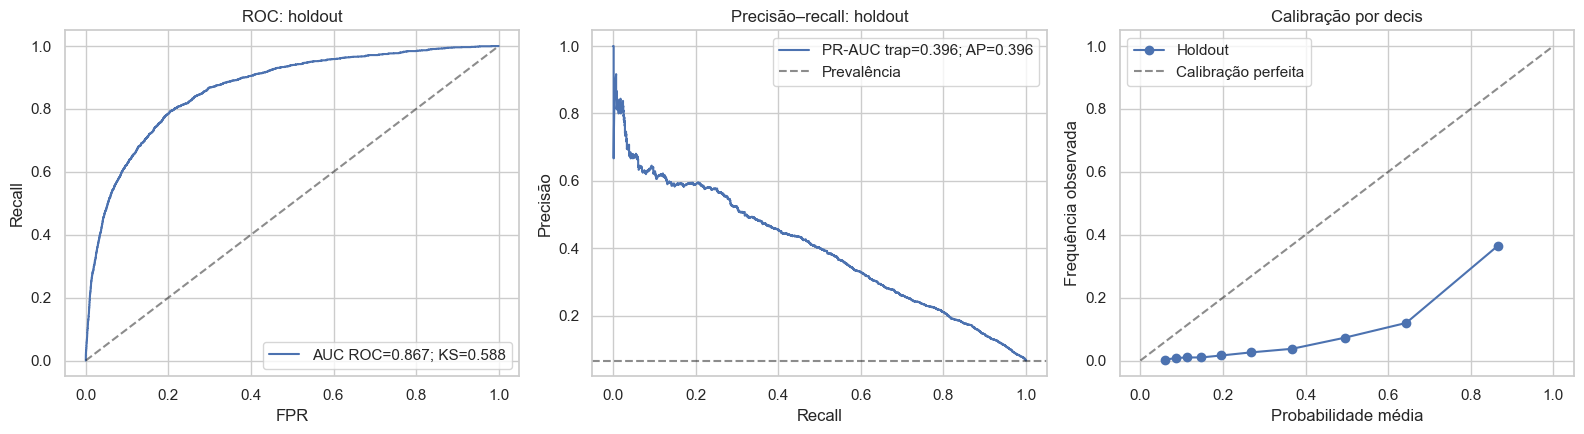

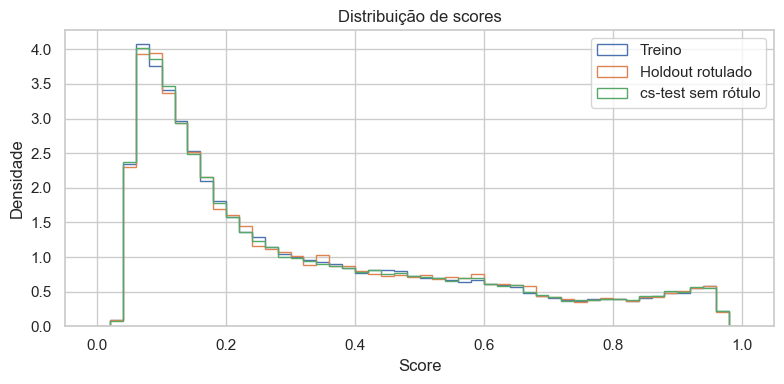

In [7]:
fig, axs = plt.subplots(1,3,figsize=(16,4.5))
fpr,tpr,_ = roc_curve(y_test,p_test)
axs[0].plot(fpr,tpr,label=f"AUC ROC={roc_auc_score(y_test,p_test):.3f}; KS={np.max(tpr-fpr):.3f}")
axs[0].plot([0,1],[0,1],'k--',alpha=.5)
axs[0].set(xlabel='FPR',ylabel='Recall',title='ROC: holdout')
axs[0].legend()
pr,rc,_ = precision_recall_curve(y_test,p_test)
axs[1].plot(rc,pr,label=f"PR-AUC trap={auc(rc,pr):.3f}; AP={average_precision_score(y_test,p_test):.3f}")
axs[1].axhline(y_test.mean(),color='k',ls='--',alpha=.5,label='Prevalência')
axs[1].set(xlabel='Recall',ylabel='Precisão',title='Precisão–recall: holdout')
axs[1].legend()
frac,mean_pred = calibration_curve(y_test,p_test,n_bins=10,strategy='quantile')
axs[2].plot(mean_pred,frac,marker='o',label='Holdout')
axs[2].plot([0,1],[0,1],'k--',alpha=.5,label='Calibração perfeita')
axs[2].set(xlabel='Probabilidade média',ylabel='Frequência observada',title='Calibração por decis')
axs[2].legend()
plt.tight_layout(); plt.show()

fig,ax = plt.subplots(figsize=(8,4))
bins=np.linspace(0,1,51)
ax.hist(p_train,bins=bins,density=True,histtype='step',lw=2,label='Treino')
ax.hist(p_test,bins=bins,density=True,histtype='step',lw=2,label='Holdout rotulado')
ax.hist(p_cs_test,bins=bins,density=True,histtype='step',lw=2,label='cs-test sem rótulo')
ax.set(xlabel='Score',ylabel='Densidade',title='Distribuição de scores')
ax.legend(); plt.tight_layout(); plt.show()

## 6. Registrar proveniência

O manifesto impede que uma execução posterior confunda esta reconstrução com o objeto original não persistido.

In [8]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()

manifesto = {
    'status':'retreino com scale_pos_weight=13.882494684620836; nao e o Booster original',
    'variant':'metricas_brier_auc_prauc_ks_grade_5a50',
    'model_sha256':sha256(MODEL_PATH),
    'fonte_notebook':'reference/model_final.ipynb',
    'fonte_training_sha256':sha256(train_path),
    'fonte_cs_test_sha256':sha256(test_path),
    'features':FEATURES,
    'target':TARGET,
    'seed_split':SEED,
    'split':{'teste':0.15,'validacao_de_treino_mais_validacao':0.1765,'stratify':False},
    'params_fornecidos':PARAMS_VARIANTE,
    'xgboost_versao':xgb.__version__,
    'num_boosted_rounds':model_class.num_boosted_rounds(),
    'best_iteration':model_class.best_iteration,
    'politica_predicao':'Booster.predict sem iteration_range; todas as arvores, como model_final.ipynb',
    'cutoff':THRESHOLD,
    'baseline_holdout':{k:float(v) for k,v in metricas(y_test,p_test).items()}
}
if RETRAIN_MODEL:
    MANIFEST_PATH.write_text(json.dumps(manifesto,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Novo manifesto salvo:', MANIFEST_PATH)
else:
    manifesto_congelado = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
    assert manifesto_congelado['model_sha256'] == sha256(MODEL_PATH), 'Modelo e manifesto divergentes.'
    assert manifesto_congelado['fonte_training_sha256'] == sha256(train_path), 'Treino diferente da fonte registrada.'
    for chave in ('auc_roc', 'pr_auc_trap', 'ks_modelo', 'brier'):
        assert np.isclose(manifesto['baseline_holdout'][chave],
                          manifesto_congelado['baseline_holdout'][chave],
                          rtol=0, atol=1e-6), f'Linha de base divergente: {chave}'
    manifesto = manifesto_congelado
    print('Manifesto congelado verificado:', MANIFEST_PATH)
print('AUC do holdout:',round(manifesto['baseline_holdout']['auc_roc'],4))

Manifesto congelado verificado: .\models\manifesto_modelo.json
AUC do holdout: 0.8668
